In [20]:
import os
import ast
from typing import Tuple, List, Optional
import warnings

import torch
import numpy as np
import pandas as pd
from thgsp.graphs.core import SparseTensor, GraphBase
from baselines.graph_signal_sampling import sampling_and_reconstruction, build_graph_from_edge_index

from data.dataset import (
    GraphSignalDataset,
    create_splits_from_indices
)
from data.utils_io import load_config, load_json
from visualization.gwt_coeffs import visualize_grid_graph_sgwt_coefficients, visualize_grid_graph_inverse_sgwt_reconstruction, visualize_energy_distribution_across_scales
from paths import ROOT_PROJECT_PATH

In [6]:
# Suppress the specific warning from thgsp
warnings.filterwarnings('ignore', message='.*Exited postprocessing with accuracies.*')

In [7]:
local_storage_dir = os.path.join(ROOT_PROJECT_PATH, "local_storage")
run_dir = os.path.join(local_storage_dir, 'runs', '2025-10-31_21-42-33')
pretraining_config = load_config(config_dir=run_dir,
                                 config_name='reconstructor_pretraining_config.json')
base_data_dir = pretraining_config.base_data_dir
split_indices = load_json(filename='split_indices.json', save_dir=run_dir)
dataset = GraphSignalDataset(base_data_dir=base_data_dir)
train_dataset, val_dataset, test_dataset = create_splits_from_indices(dataset=dataset,
                                                                      train_indices=split_indices['train'],
                                                                      val_indices=split_indices['val'],
                                                                      test_indices=split_indices['test'])
# data
target_dataset = test_dataset
num_samples = len(target_dataset)

In [8]:
hparam_dirs = {
    'ess': os.path.join(local_storage_dir, 'gsss_hparams/2025-11-18_03-05-51/ess'),
    'bsgda': os.path.join(local_storage_dir, 'gsss_hparams/2025-11-18_03-05-51/bsgda'),
    'fastgsss': os.path.join(local_storage_dir, 'gsss_hparams/2025-11-18_09-47-14/fastgsss'),
    'rsbs': os.path.join(local_storage_dir, 'gsss_hparams/2025-11-18_12-17-44/rsbs'),
}

In [9]:
def load_best_params_raw(method_name, hparam_dirs):
    hparam_dir = hparam_dirs[method_name]
    file_path = os.path.join(hparam_dir, 'best_params.txt')
    with open(file_path, 'r') as f:
        content = f.read()
        best_params = ast.literal_eval(content)
    return best_params

In [18]:
def monte_carlo_averaging_sampling_and_reconstruction(
        method_name: str,
        x: torch.Tensor,
        args,
        params,
        k_mc: int,
) -> Tuple[List[List[int]], torch.Tensor]:
    samples = []
    reconstructions = []
    for _ in range(k_mc):
        S, x_hat = sampling_and_reconstruction(
            method_name=method_name,
            x=x,
            args=args,
            search_params=params,
        )
        samples.append(S)
        reconstructions.append(x_hat)
    reconstructions = torch.stack(reconstructions, dim=0)
    x_hat_mc = reconstructions.mean(dim=0)
    return samples, x_hat_mc

 ****************** Method: ess ****************** 
Sample 1 - Sample Size / Num Nodes: 300/600=0.50


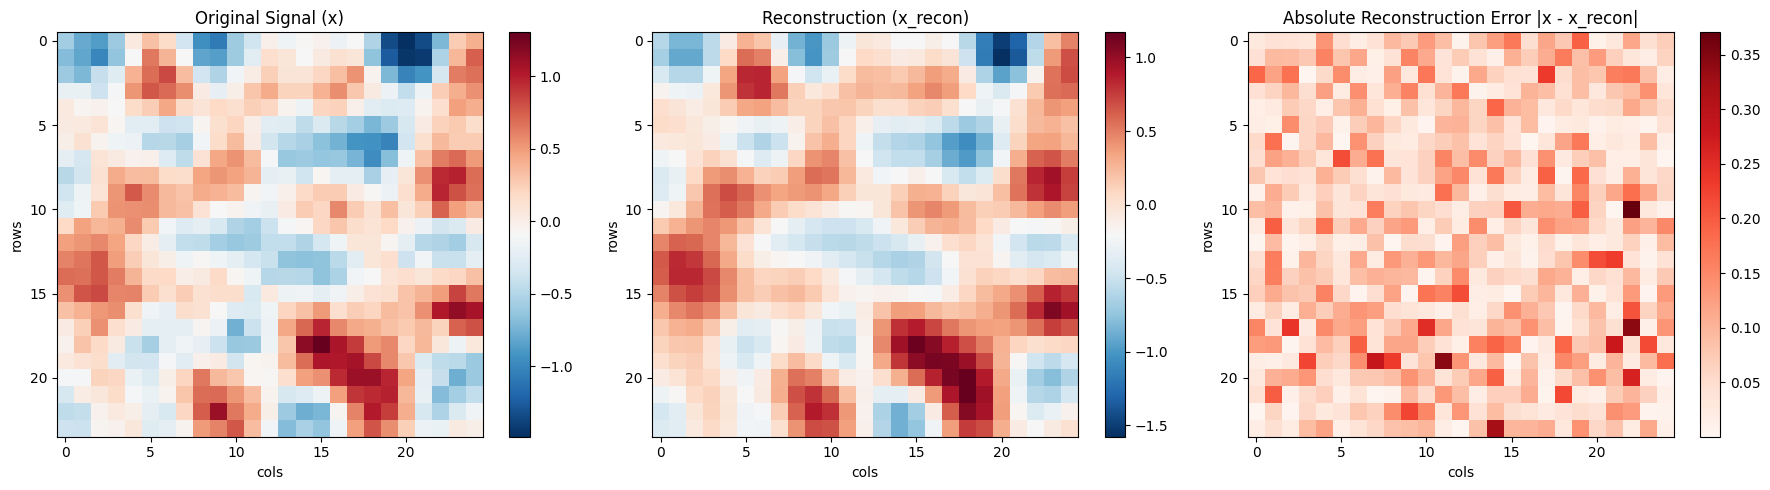

Max absolute error: 0.370573
Mean squared error: 0.009245
RMSE: 0.096153
Sample 17 - Sample Size / Num Nodes: 84/168=0.50


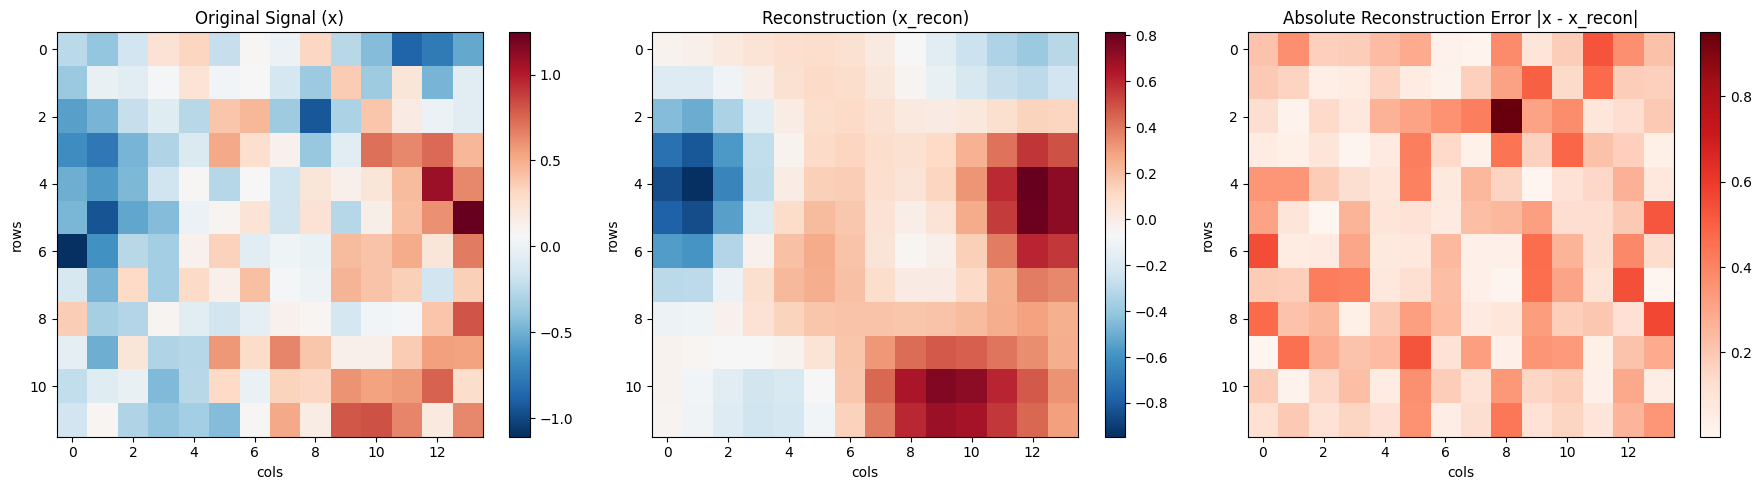

Max absolute error: 0.949736
Mean squared error: 0.066222
RMSE: 0.257337
 ****************** Method: bsgda ****************** 
Sample 1 - Sample Size / Num Nodes: 300/600=0.50


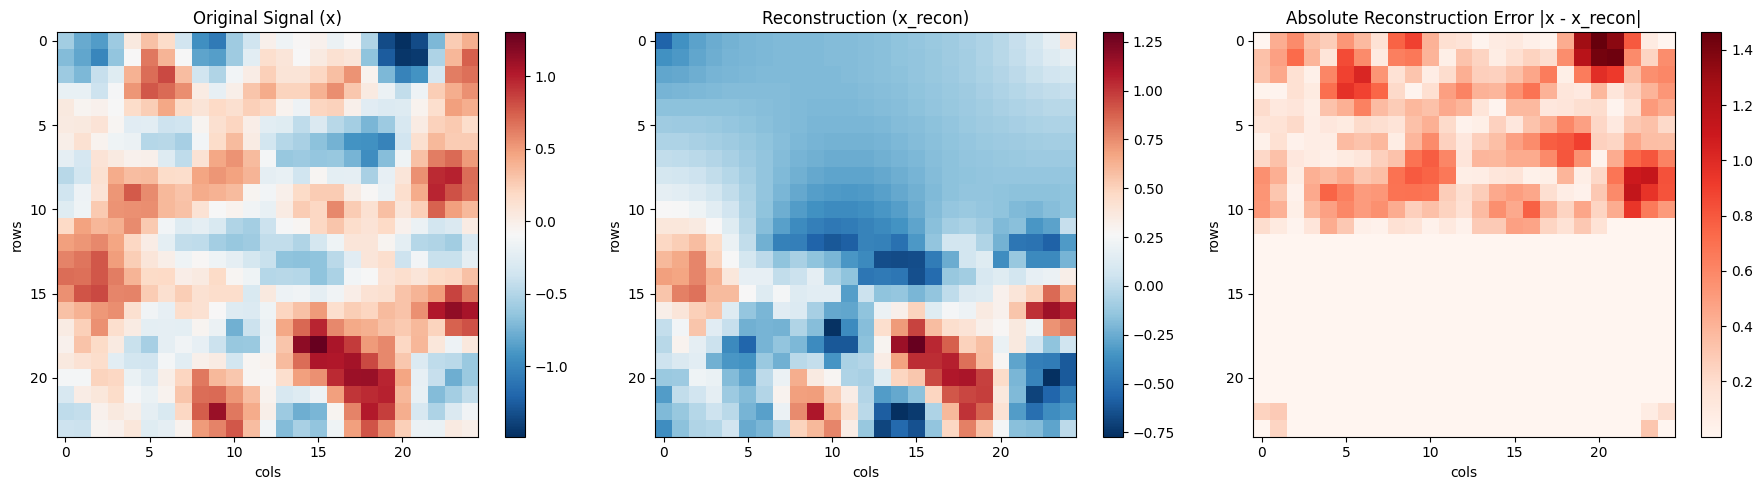

Max absolute error: 1.463280
Mean squared error: 0.113275
RMSE: 0.336564
Sample 17 - Sample Size / Num Nodes: 84/168=0.50


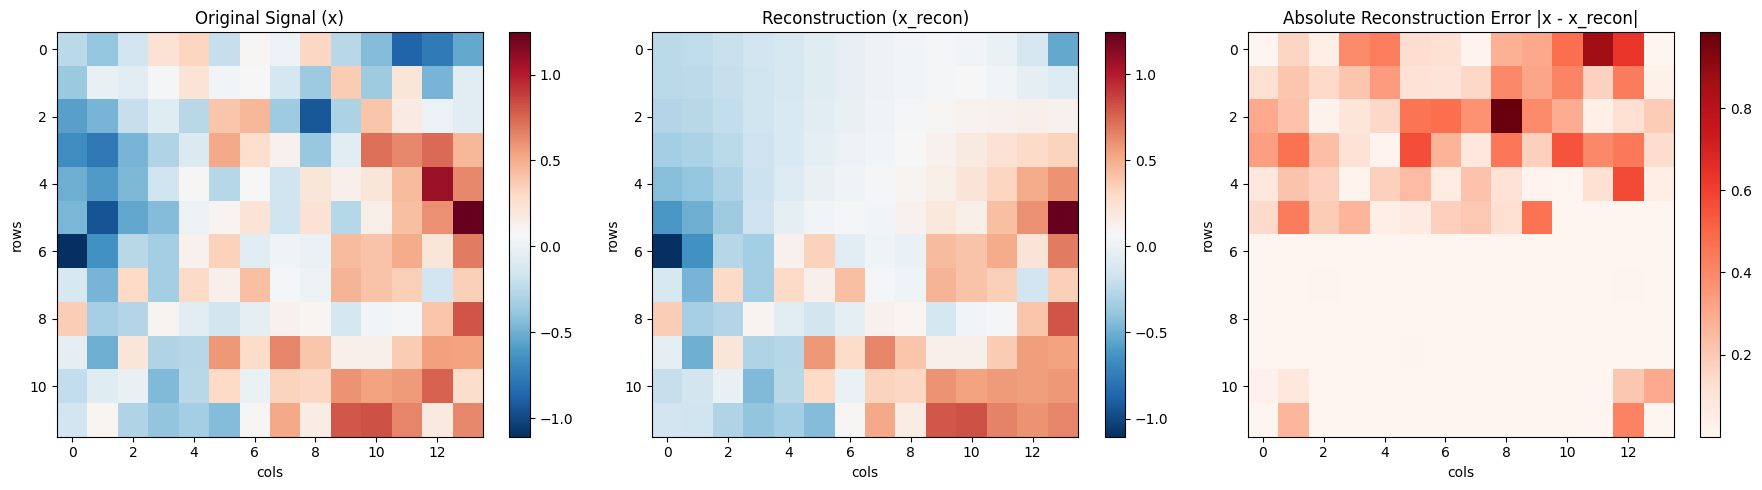

Max absolute error: 0.984730
Mean squared error: 0.048650
RMSE: 0.220568
 ****************** Method: fastgsss ****************** 
Sample 1 - Sample Size / Num Nodes: 300/600=0.50


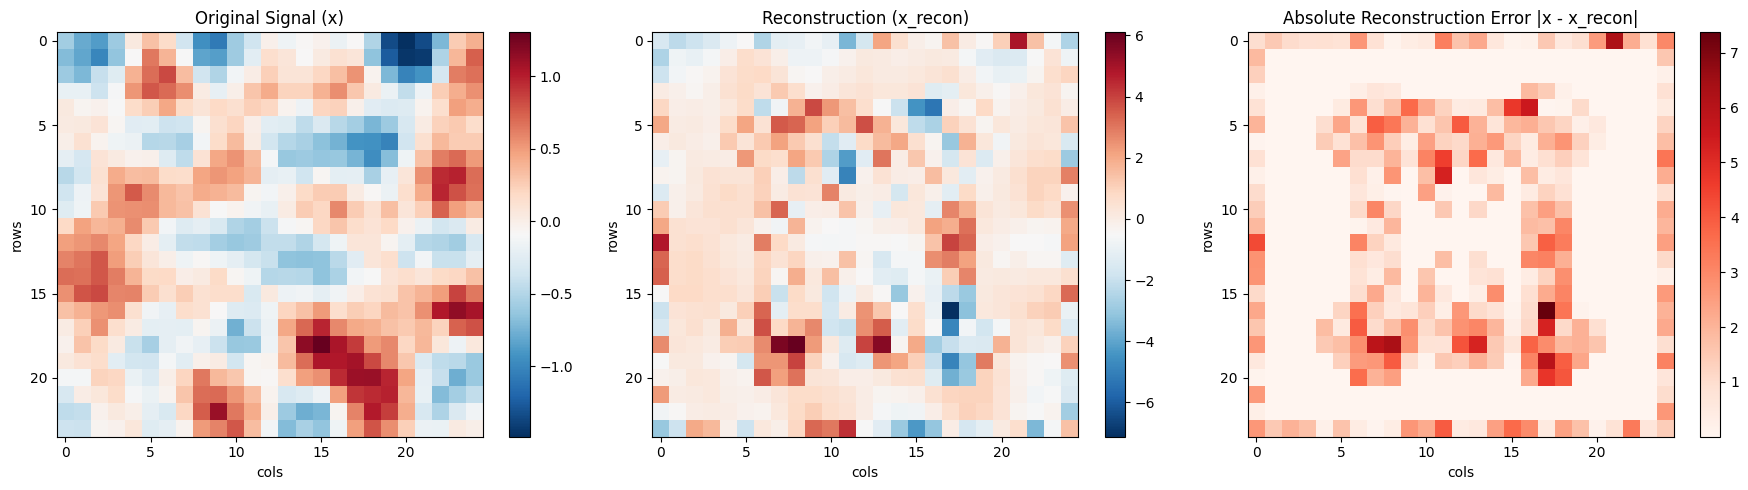

Max absolute error: 7.372079
Mean squared error: 2.308528
RMSE: 1.519384
Sample 17 - Sample Size / Num Nodes: 84/168=0.50


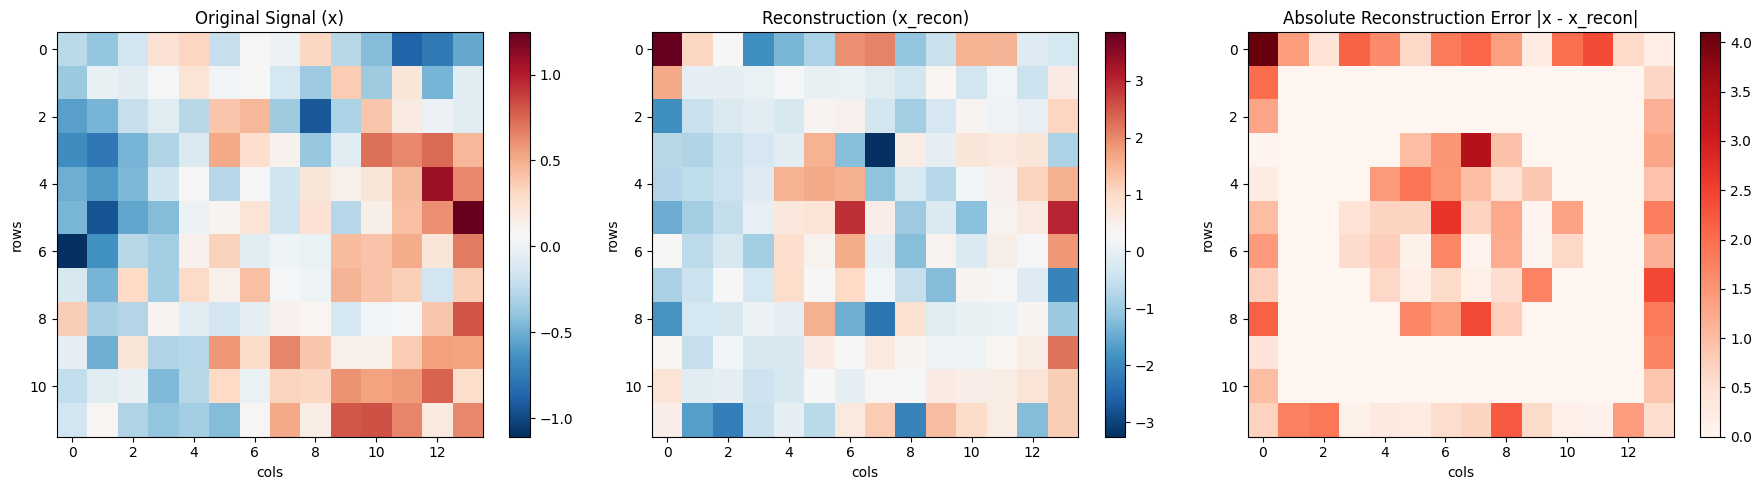

Max absolute error: 4.101312
Mean squared error: 0.932407
RMSE: 0.965612
 ****************** Method: rsbs ****************** 
Sample 1 - Sample Size / Num Nodes: 300/600=0.50


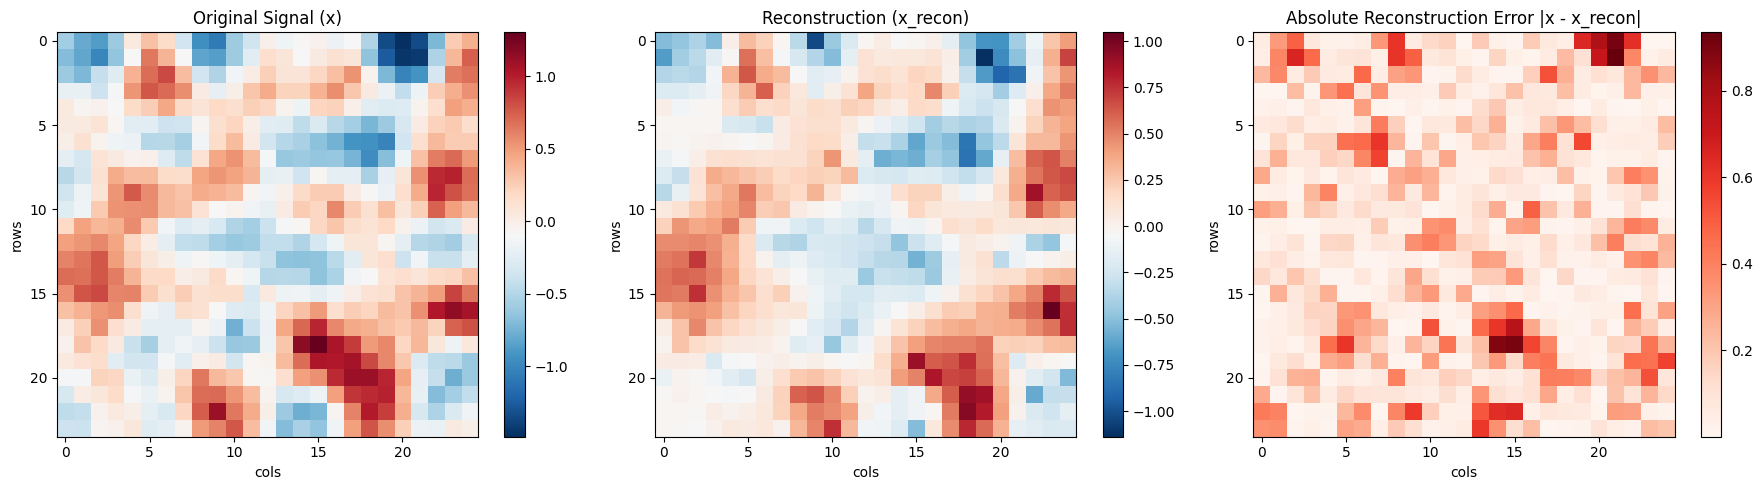

Max absolute error: 0.934466
Mean squared error: 0.050262
RMSE: 0.224192
Sample 17 - Sample Size / Num Nodes: 84/168=0.50


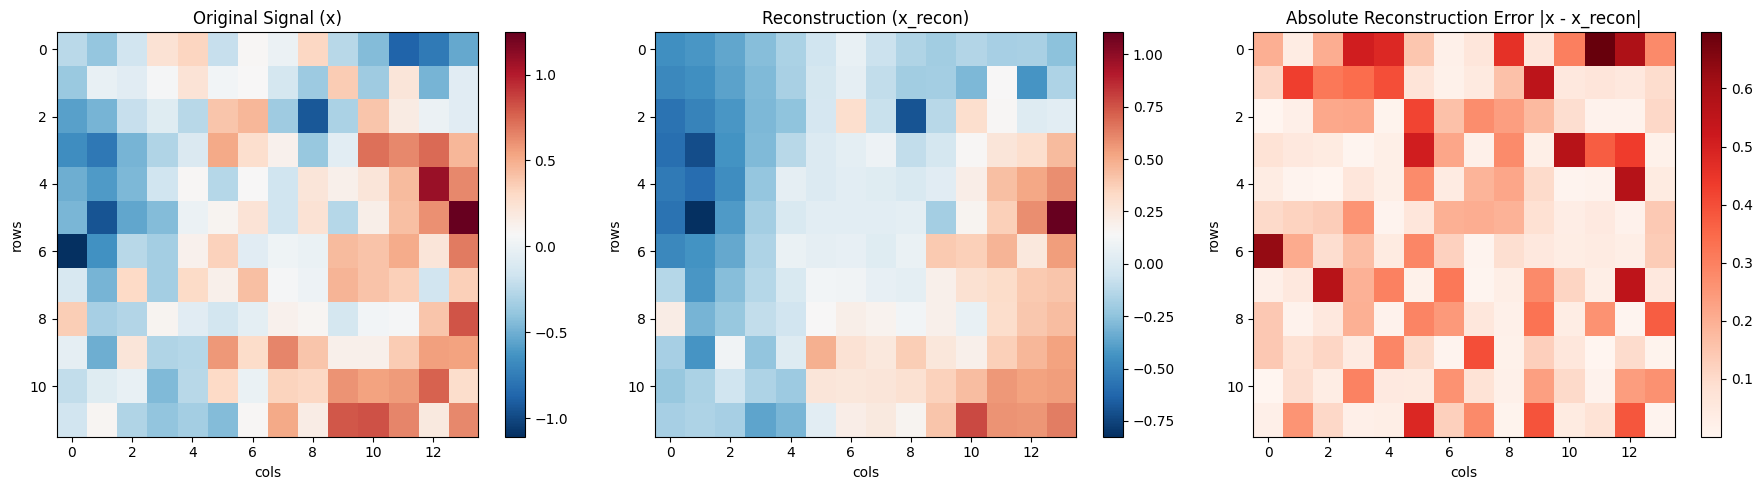

Max absolute error: 0.696587
Mean squared error: 0.050675
RMSE: 0.225112


In [37]:
# keep_ratio = pretraining_config.keep_ratio
num_filters = 5
keep_ratio = 0.1 * num_filters

results = {}
for method_name in ['ess', 'bsgda', 'fastgsss', 'rsbs']:
    print(f" ****************** Method: {method_name} ****************** ")
    # loading the hparams of the method
    best_params = load_best_params_raw(method_name, hparam_dirs)
    method_mse_x = []
    method_mse_x_clean = []
    # method_mse_x_mc = []
    # method_mse_x_clean_mc = []
    for i in range(num_samples):
        if i not in [0, 16]:
            continue
        data = target_dataset[i]
        num_nodes = data.num_nodes
        rows=data['graph_metadata']['height']
        cols=data['graph_metadata']['width']

        edge_index = data.edge_index  # (2, num_edges)
        x = data.x  # (num_nodes, 1)
        x_clean = torch.tensor(data['signal_metadata']['x_clean'], dtype=torch.float32)
        bandwidth = data.signal_metadata['R']

        sample_size = min(int(num_nodes * keep_ratio), num_nodes)
        print(f"Sample {i + 1} - Sample Size / Num Nodes: {sample_size}/{num_nodes}={sample_size/num_nodes:.2f}", )

        # THGSP graph
        thgsp_graph, thgsp_adj = build_graph_from_edge_index(edge_index=edge_index,
                                                       num_nodes=num_nodes,
                                                       x=x)
        thgsp_L_sym = thgsp_graph.L("sym")
        thgsp_L_comb = thgsp_graph.L("comb")
        thgsp_eigenvalues, thgsp_eigenvectors = thgsp_graph.spectral(lap_type="sym")
        args = {
            'x_clean': x_clean,
            'thgsp_graph': thgsp_graph,
            'thgsp_adj': thgsp_adj,
            'thgsp_L_sym': thgsp_L_sym,
            'thgsp_L_comb': thgsp_L_comb,
            'thgsp_eigenvalues': thgsp_eigenvalues,
            'thgsp_eigenvectors': thgsp_eigenvectors,
            'signal_bandwidth': bandwidth,
            'sample_size': sample_size,
            'num_nodes': num_nodes,
        }
        S, x_hat = sampling_and_reconstruction(
            method_name=method_name,
            x=x,
            args=args,
            search_params=best_params,
        )
        # S_list, x_hat_mc = monte_carlo_averaging_sampling_and_reconstruction(
        #     method_name=method_name,
        #     x=x,
        #     args=args,
        #     params=best_params,
        #     k_mc=20,
        # )
        visualize_grid_graph_inverse_sgwt_reconstruction(x_recon=x_hat,
                                                         x=x,
                                                         rows=rows,
                                                         cols=cols,
                                                         save_fig=False)
        # visualize_grid_graph_inverse_sgwt_reconstruction(x_recon=x_hat,
        #                                                  x=x_clean,
        #                                                  rows=rows,
        #                                                  cols=cols,
        #                                                  save_fig=False)
        mse_x = ((x.squeeze() - x_hat.squeeze()) ** 2).mean().item()
        # mse_x_mc = ((x.squeeze() - x_hat_mc.squeeze()) ** 2).mean().item()
        mse_x_clean = ((x_clean.squeeze() - x_hat.squeeze()) ** 2).mean().item()
        # mse_x_clean_mc = ((x_clean.squeeze() - x_hat_mc.squeeze()) ** 2).mean().item()


        method_mse_x.append(mse_x)
        method_mse_x_clean.append(mse_x_clean)
        # method_mse_x_mc.append(mse_x_mc)
        # method_mse_x_clean_mc.append(mse_x_clean_mc)
    # break
    results[method_name] = {
        'mse_x': method_mse_x,
        'mse_x_clean': method_mse_x_clean,
        # 'mse_x_mc': method_mse_x_mc,
        # 'mse_x_clean_mc': method_mse_x_clean_mc,
    }


In [28]:
# Compute statistics for each method
stats_data = []

for method_name, method_results in results.items():
    # Calculate mean and std for each metric
    mse_x_mean = np.mean(method_results['mse_x'])
    mse_x_std = np.std(method_results['mse_x'])

    mse_x_clean_mean = np.mean(method_results['mse_x_clean'])
    mse_x_clean_std = np.std(method_results['mse_x_clean'])

    # mse_x_mc_mean = np.mean(method_results['mse_x_mc'])
    # mse_x_mc_std = np.std(method_results['mse_x_mc'])

    # mse_x_clean_mc_mean = np.mean(method_results['mse_x_clean_mc'])
    # mse_x_clean_mc_std = np.std(method_results['mse_x_clean_mc'])

    # Format as "mean ± std"
    stats_data.append({
        'Method': method_name.upper(),
        'MSE(x)': f"{mse_x_mean:.4f} ± {mse_x_std:.4f}",
        'MSE(x_clean)': f"{mse_x_clean_mean:.4f} ± {mse_x_clean_std:.4f}",
        # 'MSE(x_mc)': f"{mse_x_mc_mean:.2f} ± {mse_x_mc_std:.2f}",
        # 'MSE(x_clean_mc)': f"{mse_x_clean_mc_mean:.2f} ± {mse_x_clean_mc_std:.2f}"
    })

# Create DataFrame
df_stats = pd.DataFrame(stats_data)

# Display the table
print("\n" + "="*100)
print("Performance Comparison Table (Mean ± Std)")
print("="*100)
print(df_stats.to_string(index=False))
print("="*100)

# Optionally, save to CSV
df_stats.to_csv('method_comparison_results.csv', index=False)
print("\nTable saved to 'method_comparison_results.csv'")


Performance Comparison Table (Mean ± Std)
  Method               MSE(x)         MSE(x_clean)
     ESS      0.0394 ± 0.0272      0.0071 ± 0.0069
   BSGDA      0.1282 ± 0.1118      0.1321 ± 0.1106
FASTGSSS 468.8983 ± 1904.6186 468.6273 ± 1903.6558
    RSBS      0.0782 ± 0.0657      0.0638 ± 0.0595

Table saved to 'method_comparison_results.csv'
